In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import mannwhitneyu
from scipy.stats import ttest_ind

/life/PMO/liqing/env/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/life/PMO/liqing/env/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.2' currently installed).
  from pandas.core import (


####计算从文章中收集到的CD8验证的肽段的亲和力预测得分与免疫原性的关系

In [2]:
def plot_box(filename,aimname,outname):
    df = pd.read_csv(filename,sep="\t",header=0)
    response=df[df['Response']=="CD8+"][aimname]
    noresponse=df[df['Response']=="CD8-"][aimname]  
    maxl=np.max(df[aimname])
    #print(noresponse)
    print('positive mean',np.mean(response))
    print('negative mean',np.mean(noresponse))

    print('positive median',np.median(response))
    print('negative median',np.median(noresponse))
    # 执行秩和检验（Mann-Whitney U 检验）
    statistic, p_value = mannwhitneyu(response, noresponse)
    # 打印结果
    print("Mann-Whitney U 检验结果：")
    print(f"统计量：{statistic}")
    print(f"p 值：{p_value}")

    # 执行 t 检验（独立样本 t 检验）
    statistic, p_value = ttest_ind(response, noresponse)
    # 打印结果
    print("独立样本 t 检验结果：")
    print(f"统计量：{statistic}")
    print(f"p 值：{p_value}")
    
    '''
    grouped_data = df.groupby('Response')['HLA'].apply(list)
    colors = ['red', 'blue']
    #print(grouped_data)
    # 创建一个新的图形，并设置大小
    plt.figure(figsize=(3, 5))

    # 绘制箱线图
    plt.boxplot(grouped_data,widths=0.4)
    # 设置横坐标刻度名称
    plt.xticks(range(1, len(grouped_data) + 1), grouped_data.index)
    '''
    plt.figure(figsize=(3, 4))
    # 按照组别分组
    grouped_data = [df[df['Response'] == 'CD8+'][aimname], df[df['Response'] == 'CD8-'][aimname]]

    
    # 设置箱线图的颜色
    boxplot = plt.boxplot(grouped_data, widths=0.4, patch_artist=True)

    # 绘制箱线图
    # 设置每个箱体的颜色
    colors = ['#C4372E', '#AAAAAA']
    for box, color in zip(boxplot['boxes'], colors):
        box.set(facecolor=color)
    # 设置x轴标签
    plt.xticks([1, 2], ['CD8+', 'CD8-'])

    # 添加 x 轴标签和标题
    plt.xlabel('Response')
    plt.ylabel(aimname)
    title="Boxplot of "+aimname+" by Response"
    plt.title(title)
    plt.xticks()
    ymax=maxl+maxl*0.2
    plt.ylim(0,ymax)
    pinfor="p-value="+str(round(p_value,6))
    plt.text(1.25, 1,pinfor)
    outplot="Table_"+outname+"_"+aimname+"_boxplot.svg"
    outplot=outplot.replace(" ","_")
    plt.savefig(outplot)
    plt.show()

positive mean 0.70939358380182
negative mean 0.4288393589667976
positive median 0.9621614813804626
negative median 0.2655478417873382
Mann-Whitney U 检验结果：
统计量：2034.0
p 值：5.425937724519667e-05
独立样本 t 检验结果：
统计量：3.6818089367035247
p 值：0.00036924191352088076


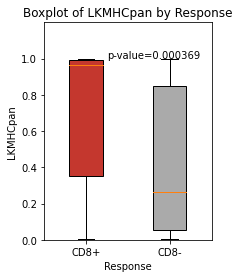

positive mean 1.0446140350877193
negative mean 1.4441836734693878
positive median 0.134
negative median 0.799
Mann-Whitney U 检验结果：
统计量：623.5
p 值：9.82300621165344e-07
独立样本 t 检验结果：
统计量：-0.7793797251839555
p 值：0.437526016806153


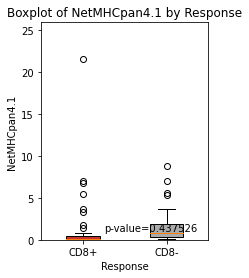

In [3]:
fileinput="Table_CD8_106_merged_lk_net_predict.xls"
plot_box(fileinput,'LKMHCpan','CD8_paper_LKMHCpan')
plot_box(fileinput,'NetMHCpan4.1','CD8_paper_netMHCpan4.1')

TESLA的免疫原性验证集合

positive mean 0.865697054836132
negative mean 0.4896882989671207
positive median 0.984955906867981
negative median 0.46156924962997437
Mann-Whitney U 检验结果：
统计量：18776.0
p 值：1.5982062417742945e-08
独立样本 t 检验结果：
统计量：5.281607873691579
p 值：1.689081751736671e-07


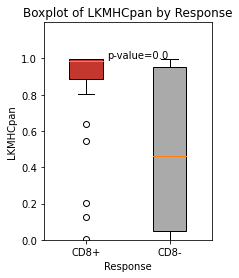

positive mean 0.15232352941176472
negative mean 1.1951837606837608
positive median 0.0435
negative median 0.461
Mann-Whitney U 检验结果：
统计量：4383.0
p 值：4.480966139195181e-10
独立样本 t 检验结果：
统计量：-2.8816571285636168
p 值：0.0040713652824130074


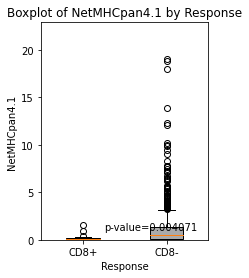

In [4]:
fileinput="Table_TESLA_merged_lk_net_predict.xls"
plot_box(fileinput,'LKMHCpan','TESLA_LKMHCpan')
plot_box(fileinput,'NetMHCpan4.1','TESLA_netMHCpan4.1')

positive mean 0.767792682869585
negative mean 0.48571812844779205
positive median 0.9736059308052064
negative median 0.4588996469974518
Mann-Whitney U 检验结果：
统计量：49324.5
p 值：4.648801405546892e-12
独立样本 t 检验结果：
统计量：6.286990998114564
p 值：5.197669203765937e-10


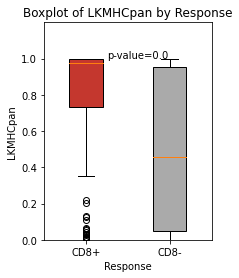

positive mean 0.7112307692307693
negative mean 1.2114300932090545
positive median 0.085
negative median 0.471
Mann-Whitney U 检验结果：
统计量：18448.5
p 值：7.222549259402745e-13
独立样本 t 检验结果：
统计量：-2.1028751457179826
p 值：0.0357736618746089


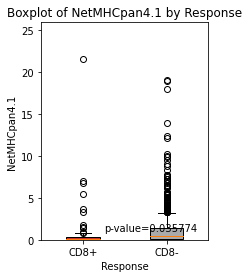

In [5]:
#合并paper和TESLA两组数据集
df_paper=pd.read_csv("Table_CD8_106_merged_lk_net_predict.xls",sep="\t",header=0)
df_TESLA=pd.read_csv("Table_TESLA_merged_lk_net_predict.xls",sep="\t",header=0)
df_combined=pd.concat([df_paper,df_TESLA],ignore_index=True)
df_combined.to_csv("Table_CD8_paper_TESLA_merged_lk_net_predict.xls",sep="\t",index=False)
plot_box("Table_CD8_paper_TESLA_merged_lk_net_predict.xls",'LKMHCpan','CD8_paper_TESLA_LKMHCpan')
plot_box("Table_CD8_paper_TESLA_merged_lk_net_predict.xls",'NetMHCpan4.1','CD8_paper_TESLA_netMHCpan4.1')